# Project Python Foundations: FoodHub Data Analysis

### Context

The number of restaurants in New York is increasing day by day. Lots of students and busy professionals rely on those restaurants due to their hectic lifestyles. Online food delivery service is a great option for them. It provides them with good food from their favorite restaurants. A food aggregator company FoodHub offers access to multiple restaurants through a single smartphone app.

The app allows the restaurants to receive a direct online order from a customer. The app assigns a delivery person from the company to pick up the order after it is confirmed by the restaurant. The delivery person then uses the map to reach the restaurant and waits for the food package. Once the food package is handed over to the delivery person, he/she confirms the pick-up in the app and travels to the customer's location to deliver the food. The delivery person confirms the drop-off in the app after delivering the food package to the customer. The customer can rate the order in the app. The food aggregator earns money by collecting a fixed margin of the delivery order from the restaurants.

### Objective

The food aggregator company has stored the data of the different orders made by the registered customers in their online portal. They want to analyze the data to get a fair idea about the demand of different restaurants which will help them in enhancing their customer experience. Suppose you are hired as a Data Scientist in this company and the Data Science team has shared some of the key questions that need to be answered. Perform the data analysis to find answers to these questions that will help the company to improve the business.

### Data Description

The data contains the different data related to a food order. The detailed data dictionary is given below.

### Data Dictionary

* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost_of_the_order: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information

### Let us start by importing the required libraries

In [2]:
# Installing the libraries with the specified version.
!pip install numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0 seaborn==0.13.2 -q --user

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [3]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

### Understanding the structure of the data

In [4]:
# uncomment and run the below code snippets if the dataset is present in the Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# Write your code here to read the data
df = pd.read_csv('/content/drive/MyDrive/foodhub_order.csv')

In [6]:
# Write your code here to view the first 5 rows
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


### **Question 1:** How many rows and columns are present in the data? [0.5 mark]

In [7]:
# Write your code here
df.shape

(1898, 9)

#### Observations:

There are 1898 rows and 9 columns

### **Question 2:** What are the datatypes of the different columns in the dataset? (The info() function can be used) [0.5 mark]

In [8]:
# Write your code here
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


#### Observations:

There are 4 int columns (order_id, customer_id, food_preparation_time, and deliver_time), 1 float column (cost_of_the_order), and 4 object columns (restaurant_name, cuisine_type, day_of_the_week, and rating)

### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method. [1 mark]

In [9]:
# Write your code here
df.isnull().sum()

,0
order_id,0
customer_id,0
restaurant_name,0
cuisine_type,0
cost_of_the_order,0
day_of_the_week,0
rating,0
food_preparation_time,0
delivery_time,0


#### Observations:

There are no missing values in the data

### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed? [2 marks]

In [10]:
# Write your code here
df.describe()

,order_id,customer_id,cost_of_the_order,food_preparation_time,delivery_time
count,1.898000e+03,1898.000000,1898.000000,1898.000000,1898.000000
mean,1.477496e+06,171168.478398,16.498851,27.371970,24.161749
std,5.480497e+02,113698.139743,7.483812,4.632481,4.972637
min,1.476547e+06,1311.000000,4.470000,20.000000,15.000000
25%,1.477021e+06,77787.750000,12.080000,23.000000,20.000000
50%,1.477496e+06,128600.000000,14.140000,27.000000,25.000000
75%,1.477970e+06,270525.000000,22.297500,31.000000,28.000000
max,1.478444e+06,405334.000000,35.410000,35.000000,33.000000


#### Observations:

Min of food_preparation_time: 20.0

Avg of food_preparation_time: 27.371970

Max of food_preparation_time: 35.0

### **Question 5:** How many orders are not rated? [1 mark]

In [11]:
# Write the code here
df['rating'].value_counts()

,count
rating,
Not given,736
5,588
4,386
3,188


#### Observations:

There are 736 unrated orders

### Exploratory Data Analysis (EDA)

### Univariate Analysis

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.) [9 marks]

### Order ID

In [12]:
# Write the code here
# Number of unique order IDs
df['order_id'].nunique()

1898

#### Observations:

There are 1898 unique order IDs

### Customer ID

In [13]:
# Number of unique customer IDs
df['customer_id'].nunique()

1200

#### Observations:

There are 1200 unique customer IDs

### Restaurant name

In [14]:
# Number of unique restaurants
df['restaurant_name'].nunique()

178

#### Observations:

There are 178 unique restaurants

### Cuisine type

In [15]:
# Number of unique cuisine types
df['cuisine_type'].nunique()

14

<Axes: xlabel='cuisine_type', ylabel='count'>

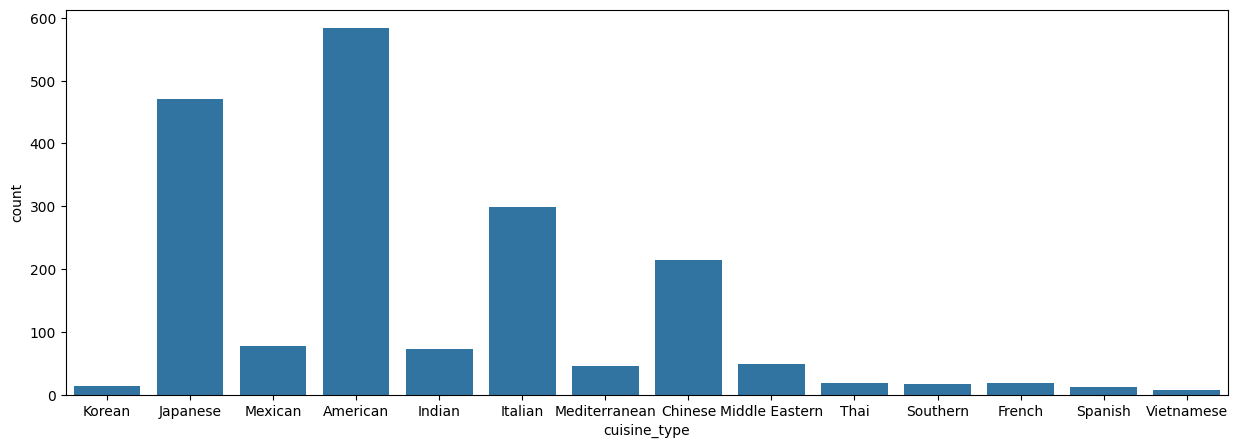

In [16]:
# Plotting countplot for cuisine type
plt.figure(figsize = (15, 5))
sns.countplot(data = df, x = 'cuisine_type')

#### Observations:

There are 14 unique cuisine types. Additionally, American has the highest count, while Vietnamese has the lowest count.

### Cost of the order

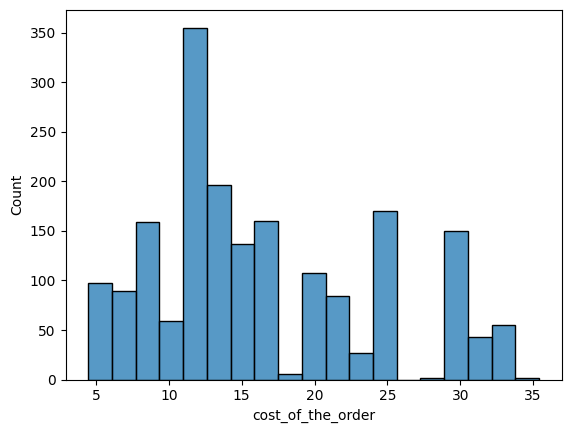

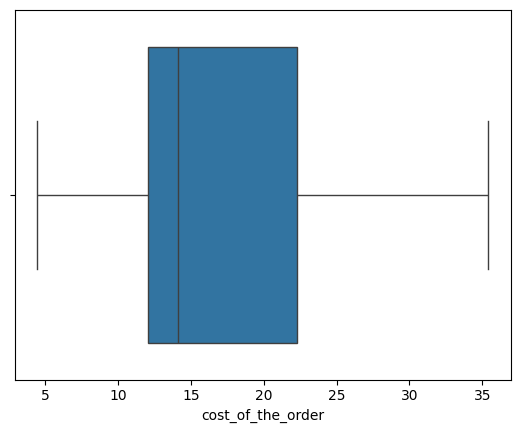

In [17]:
# Plotting histplot and boxplot for cost of the order
sns.histplot(data = df, x = 'cost_of_the_order')
plt.show()
sns.boxplot(data = df, x = 'cost_of_the_order')
plt.show()

#### Observations:

Most of the orders cost between 10 and 15 dollars. Additionally, the median cost appears to be 14 dollars, and the IQR is between approximately 12 and 23 dollars.

Max = ~35 dollars

Min = ~5 dollars

### Day of the week

In [18]:
# Counting number of entries by day of the week
df['day_of_the_week'].value_counts()

,count
day_of_the_week,
Weekend,1351
Weekday,547


<Axes: xlabel='day_of_the_week', ylabel='count'>

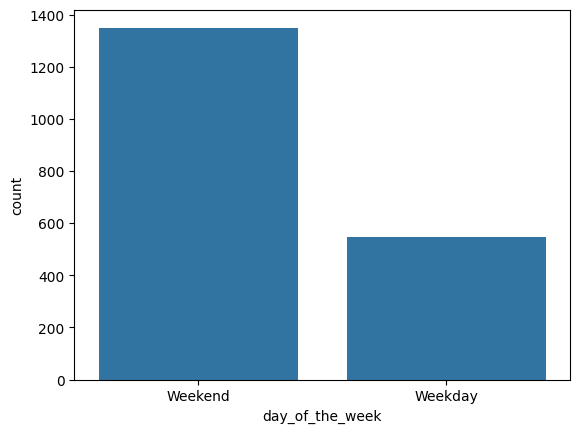

In [19]:
# Plotting countplot for day of the week
sns.countplot(data = df, x = 'day_of_the_week')

#### Observations:

Most of the orders are on the weekends.

### Rating

In [20]:
# Counting number of entries by rating
df['rating'].value_counts()

,count
rating,
Not given,736
5,588
4,386
3,188


<Axes: xlabel='rating', ylabel='count'>

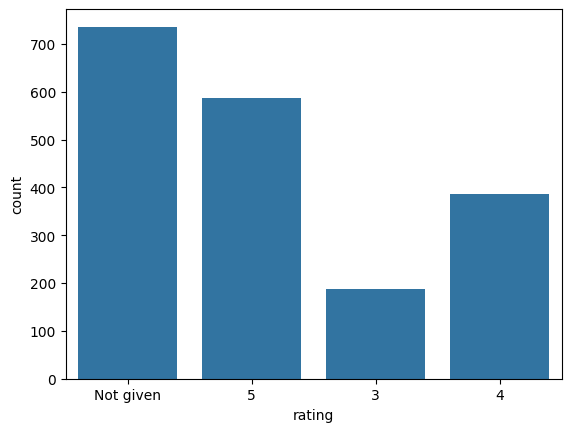

In [21]:
# Plotting countplot for rating
sns.countplot(data = df, x = 'rating')

#### Observations:

Most of the orders do not have ratings, but 5 stars is the most frequent rating.

### Food preparation time

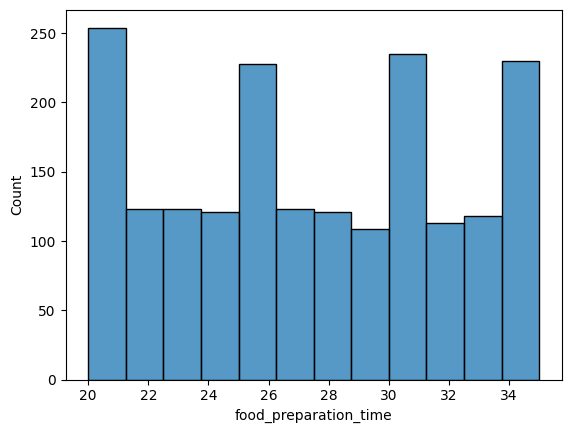

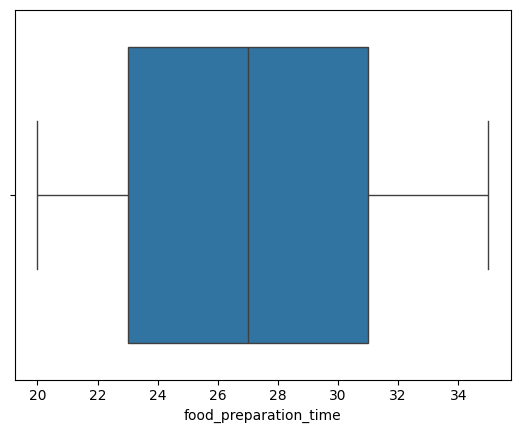

In [22]:
# Plotting histplot and boxplot for food preparation time
sns.histplot(data = df, x = 'food_preparation_time')
plt.show()
sns.boxplot(data = df, x = 'food_preparation_time')
plt.show()

#### Observations:

The median food preparation time appears to be 27 minutes, and the IQR for food preparation time is between 23 and 31 minutes.

Max = 35 minutes

Min = 20 minutes

### Delivery time

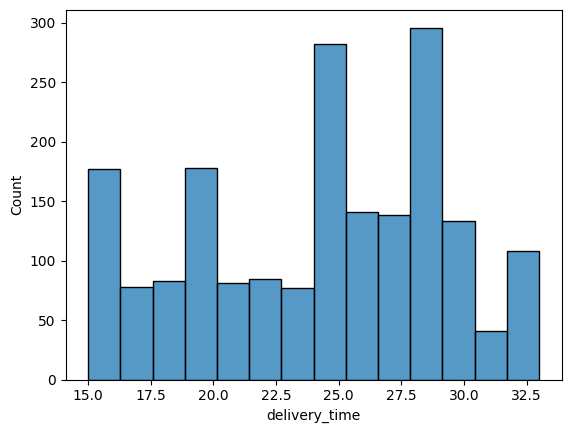

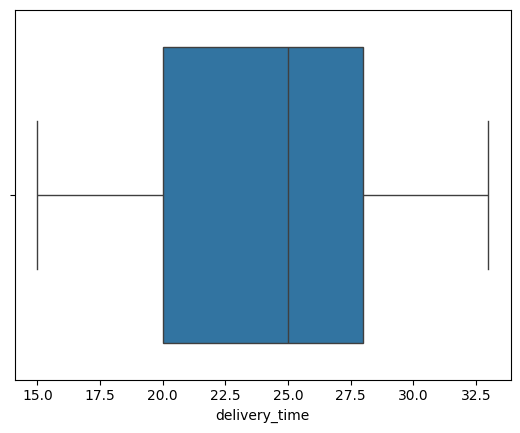

In [23]:
# Plotting histplot and boxplot for delivery time
sns.histplot(data = df, x = 'delivery_time')
plt.show()
sns.boxplot(data = df, x = 'delivery_time')
plt.show()

#### Observations:

The median delivery time appears to be 25 minutes, and the IQR for delivery time is between 20 and 28 minutes.

Max = ~33 minutes

Min = 15 minutes

### **Question 7**: Which are the top 5 restaurants in terms of the number of orders received? [1 mark]

In [24]:
# Write the code here
df['restaurant_name'].value_counts()[:5]

,count
restaurant_name,
Shake Shack,219
The Meatball Shop,132
Blue Ribbon Sushi,119
Blue Ribbon Fried Chicken,96
Parm,68


#### Observations:

The top 5 restaurants in terms of orders received are Shake Shack, The Meatball Shop, Blue Ribbon Sushi, Blue Ribbon Fried Chicken, and Parm

### **Question 8**: Which is the most popular cuisine on weekends? [1 mark]

In [25]:
# Write the code here
df[df['day_of_the_week'] == 'Weekend']['cuisine_type'].value_counts()

,count
cuisine_type,
American,415
Japanese,335
Italian,207
Chinese,163
Mexican,53
Indian,49
Middle Eastern,32
Mediterranean,32
Thai,15


#### Observations:

The top 5 most popular cuisines on the weekends are American, Japanese, Italian, Chinese, and Mexican

### **Question 9**: What percentage of the orders cost more than 20 dollars? [2 marks]

In [26]:
# Write the code here
(df[df['cost_of_the_order'] > 20].shape[0] / df.shape[0]) * 100

29.24130663856691

#### Observations:

The percentage of orders more than 20 dollars is 29.2%

### **Question 10**: What is the mean order delivery time? [1 mark]

In [27]:
# Write the code here
df['delivery_time'].mean()

np.float64(24.161749209694417)

#### Observations:

The mean order delivery time is 24.2 minutes

### **Question 11:** The company has decided to give 20% discount vouchers to the top 3 most frequent customers. Find the IDs of these customers and the number of orders they placed. [1 mark]

In [28]:
# Write the code here
df['customer_id'].value_counts()[:3]

,count
customer_id,
52832,13
47440,10
83287,9


#### Observations:

The top 3 most frequent customers are customers 52832 (13 orders), 47440 (10 orders), and 83287 (9 orders)

### Multivariate Analysis

### **Question 12**: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables) [10 marks]


### Cuisine vs Cost of the order

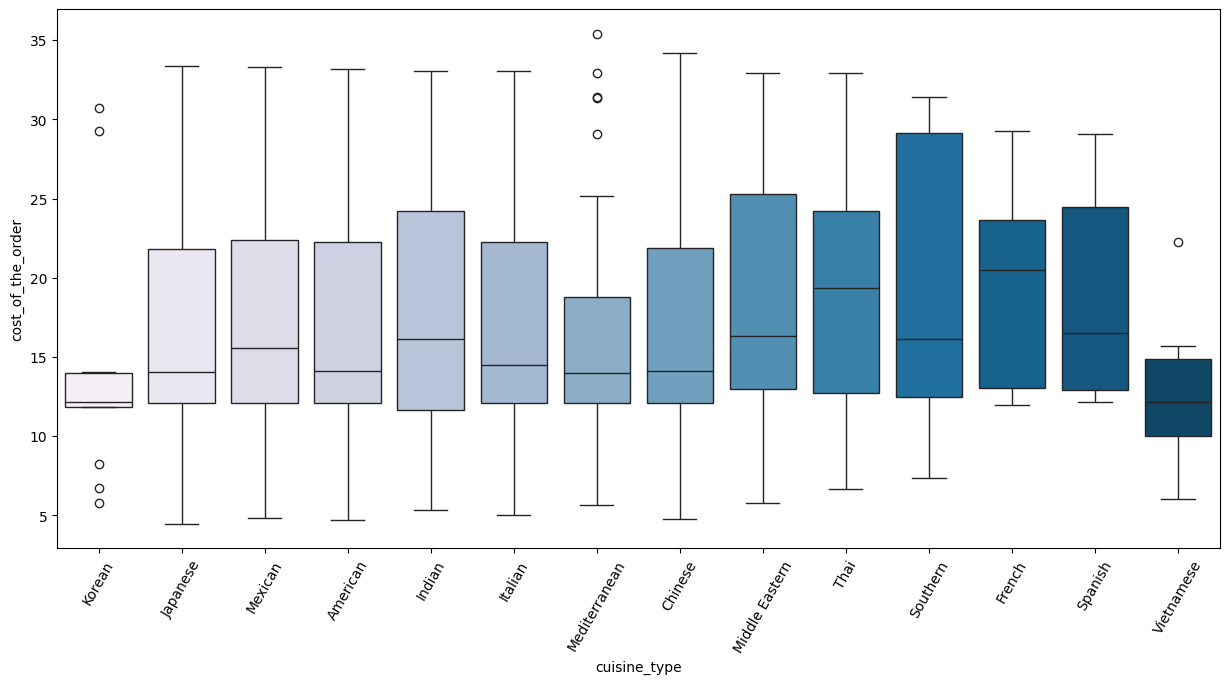

In [51]:
# Write the code here
# Plotting cuisine type VS cost of the order boxplot
plt.figure(figsize = (15, 7))
sns.boxplot(data = df, x = 'cuisine_type', y = 'cost_of_the_order', palette = 'PuBu', hue = 'cuisine_type')
plt.xticks(rotation = 60)
plt.show()

#### Observations:

Shortest IQR: Korean (12-14 dollars)

Longest IQR: Southern (14-29 dollars)

Highest Max: Chinese (35 dollars)

Lowest Max: Korean (14 dollars)

Highest Min: Korean (12 dollars)

Lowest Min: Japanese (3 dollars)

Highest Med: French (20 dollars)

Lowest Med: Vietnamese (12 dollars)

### Cuisine vs Food preparation time

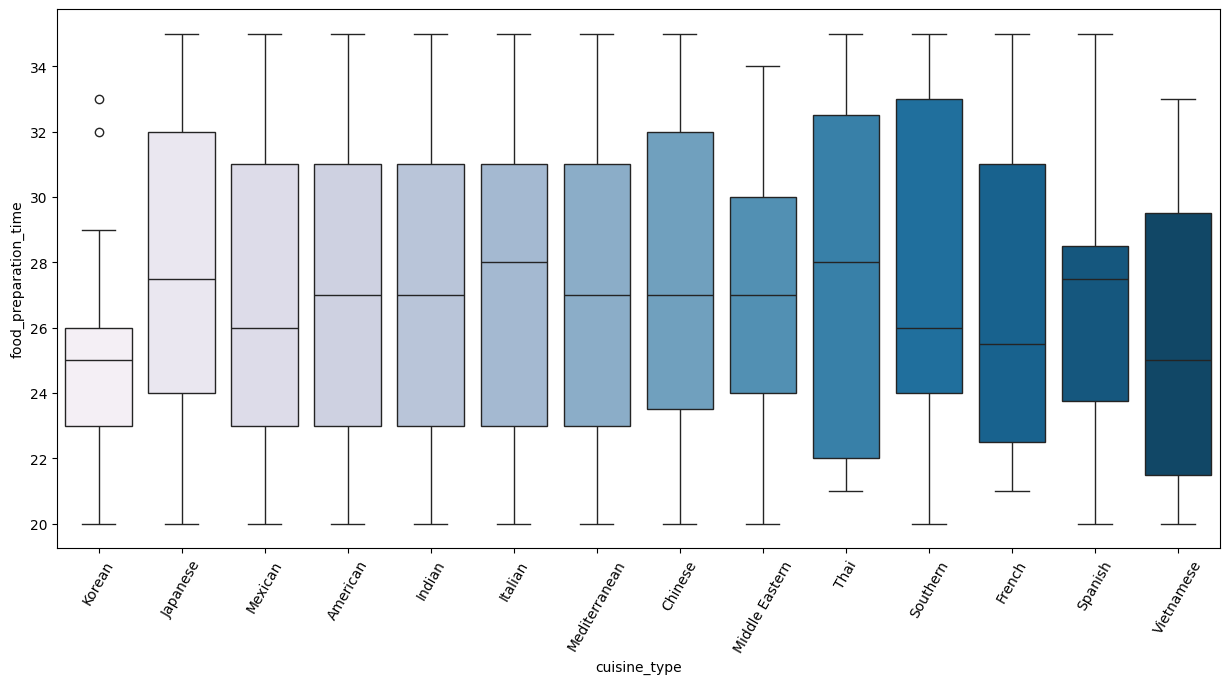

In [30]:
# Plotting cuisine type VS food preparation time boxplot
plt.figure(figsize = (15, 7))
sns.boxplot(data = df, x = 'cuisine_type', y = 'food_preparation_time', palette = 'PuBu', hue = 'cuisine_type')
plt.xticks(rotation = 60)
plt.show()

#### Observations:

Shortest IQR: Korean (23-26 min)

Longest IQR: Thai (22-32 min)

Highest Max: All except for Korean, Middle Eastern, and Vietnamese (35 min)

Lowest Max: Korean (29)

Highest Min: Thai and French (21 min)

Lowest Min: All except for Thai and French (20 min)

Highest Med: Italian and Thai (28 min)

Lowest Med: Korean and Vietnamese (25 min)

### Day of the week vs Delivery time

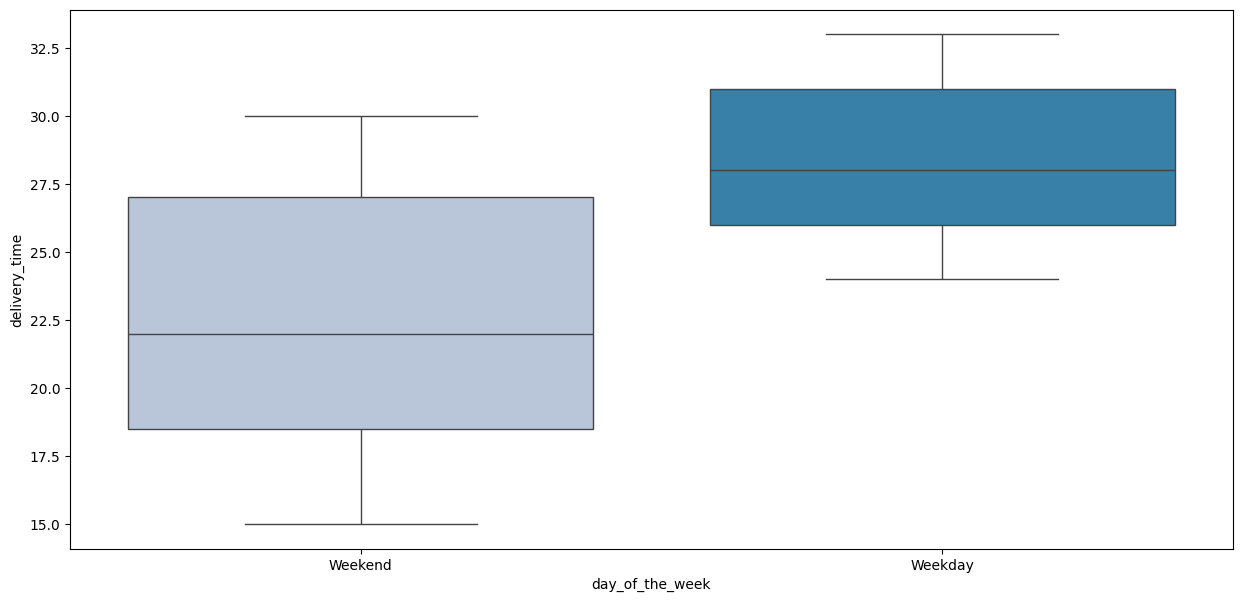

In [31]:
# Plotting day of the week VS delivery time boxplot
plt.figure(figsize = (15, 7))
sns.boxplot(data = df, x = 'day_of_the_week', y = 'delivery_time', palette = 'PuBu', hue = 'day_of_the_week')
plt.show()

#### Observations:

Weekend: Min 15.0 min, Max 30.0 min, Med 22.5 min, IQR 18.75-27.5 min

Weekday: Min 25.0 min, Max 32.5 min, Med 28.0 min, IQR 26.0-341.0 min

In [32]:
# Summations of cost of the order by restaurant name
df.groupby(['restaurant_name'])['cost_of_the_order'].sum().sort_values(ascending = False).head(14)

,cost_of_the_order
restaurant_name,
Shake Shack,3579.53
The Meatball Shop,2145.21
Blue Ribbon Sushi,1903.95
Blue Ribbon Fried Chicken,1662.29
Parm,1112.76
RedFarm Broadway,965.13
RedFarm Hudson,921.21
TAO,834.50
Han Dynasty,755.29


#### Observations:

At 3579.53 dollars, Shake Shack has generated the most money

### Rating vs Delivery time

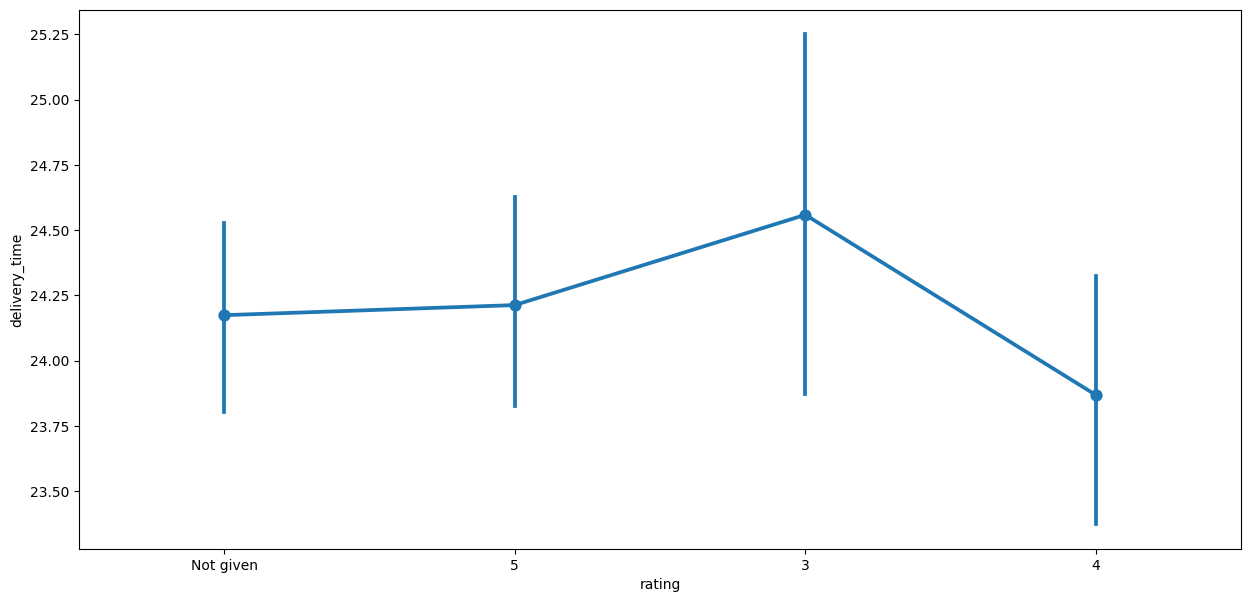

In [47]:
# Plotting rating VS delivery time pointplot
plt.figure(figsize = (15, 7))
sns.pointplot(data = df, x = 'rating', y = 'delivery_time')
plt.show()

#### Observations:

The rating of 3 has the longest range of 23.87-25.25 min and the highest mean of 24.50, meaning that longer delivery times may lead to lower star ratings.

### Rating vs Food preparation time

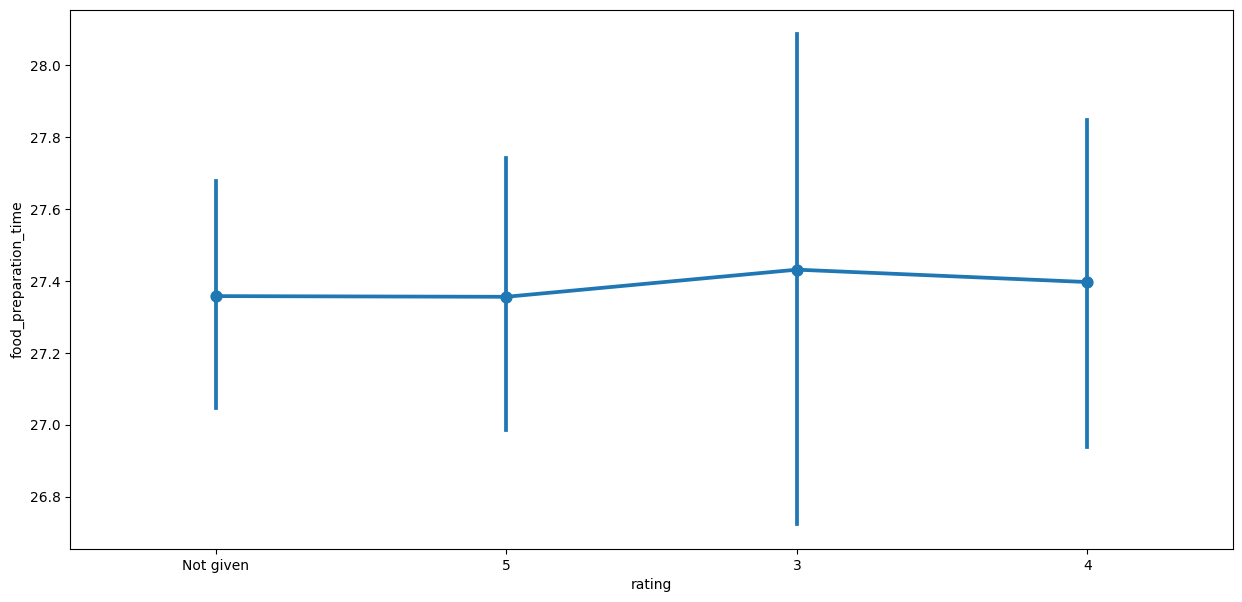

In [34]:
# Plotting rating VS food preparation time pointplot
plt.figure(figsize = (15, 7))
sns.pointplot(data = df, x = 'rating', y = 'food_preparation_time')
plt.show()

#### Observations:

The 3-star rating has the longest range of 26.6-28.2 min, but the mean is similar to the other categories. This could mean that food preparation times that are too long or too short may impact the rating.

### Rating vs Cost of the order

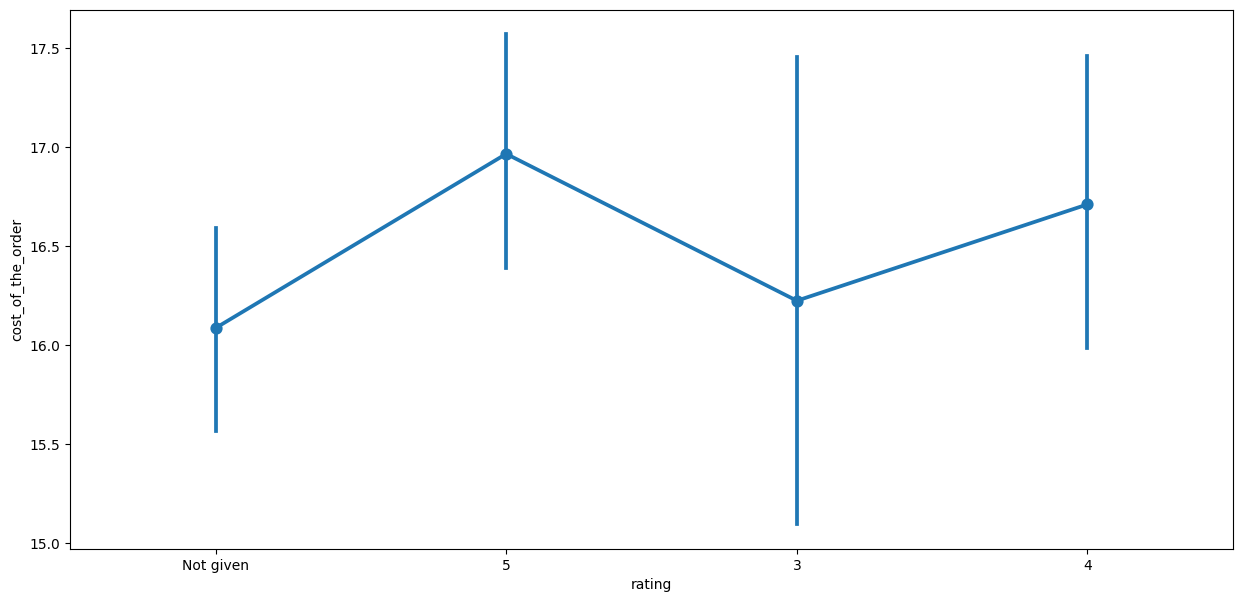

In [35]:
# Plotting rating VS cost of the order pointplot
plt.figure(figsize = (15, 7))
sns.pointplot(data = df, x = 'rating', y = 'cost_of_the_order')
plt.show()

#### Observations:

The 5-star rating has the highest mean of 17.0, while the no-star rating has the lowest median of a little over 16.0. The 3-star rating has a slightly larger mean than the no-star rating. This could mean that the cost of the order may impact the rating.

### Correlation

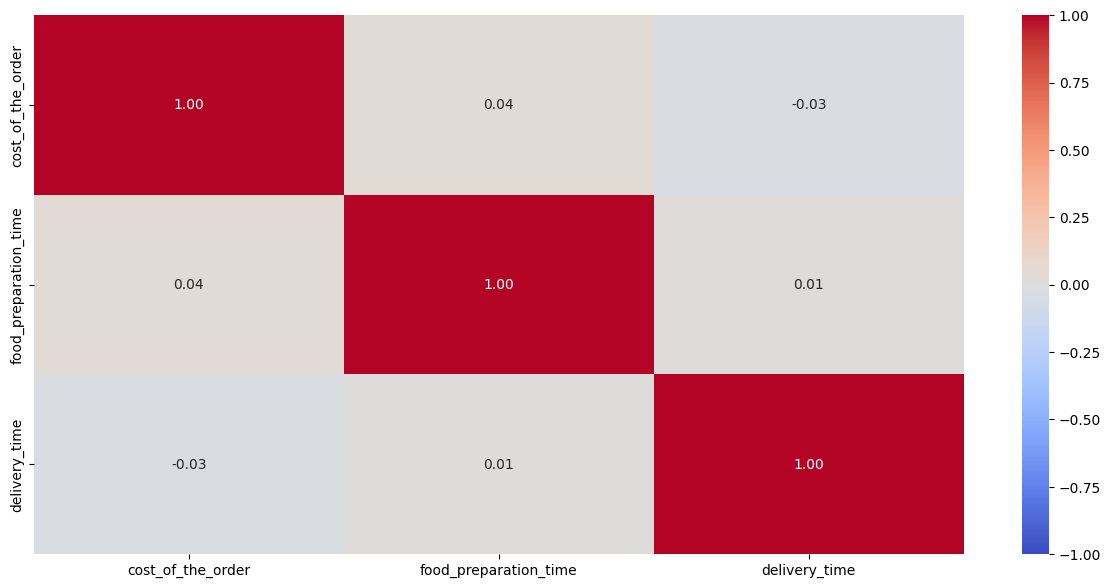

In [42]:
# Plotting heatmap of correlations between cost of the order, food preparation time, and delivery time
col = ['cost_of_the_order', 'food_preparation_time', 'delivery_time']
plt.figure(figsize = (15, 7))
sns.heatmap(df[col].corr(), annot = True, cmap = 'coolwarm', fmt = '.2f', vmin = -1, vmax = 1)
plt.show()

#### Observations:

Cost of the order and food preparation time have the highest correlation. The correlation is 0.04 (weak positive correlation).

### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer. [3 marks]

In [37]:
# Write the code here
# Counting top 5 total num of ratings by restaurant
dfrated = df[df['rating'] != 'Not given'].copy()  # Creates a copy of the dataframe without ratings that say, 'Not given'.
dfrated['rating'] = dfrated['rating'].astype(int)  # Converts rating from a str to an int
dfratingcount = dfrated.groupby(['restaurant_name'])['rating'].count().sort_values(ascending = False).reset_index()  # Groups num of ratings by restaurant name
dfratingcount.head()

,restaurant_name,rating
0,Shake Shack,133
1,The Meatball Shop,84
2,Blue Ribbon Sushi,73
3,Blue Ribbon Fried Chicken,64
4,RedFarm Broadway,41


In [38]:
# Calculating top 5 avg rating for restaurants with more than 50 ratings and more than 4 stars
rest = dfratingcount[dfratingcount['rating'] > 50]['restaurant_name']  # Resrauants with more than 50 ratings
dfmean4 = dfrated[dfrated['restaurant_name'].isin(rest)].copy()  # Creating a copy of the dataframe
dfmean4rating = dfmean4.groupby(['restaurant_name'])['rating'].mean().sort_values(ascending = False).reset_index().dropna()  # Calculating avg rating by restaurant
dfavggreater4 = dfmean4rating[dfmean4rating['rating'] > 4].sort_values(ascending = False, by = 'rating').reset_index(drop = True)  # Exlcuding avg ratings less than 4
dfavggreater4

,restaurant_name,rating
0,The Meatball Shop,4.511905
1,Blue Ribbon Fried Chicken,4.328125
2,Shake Shack,4.278195
3,Blue Ribbon Sushi,4.219178


#### Observations:

Shake Shack has the most ratings (133), but The Meatball Shop has the highest avg rating of 4.51 out of 5 stars, after excluding restaurants with fewer than 50 total ratings and ratings less than 4 stars.

### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders. [3 marks]

In [39]:
# Write the code here
# Defining a function called 'rev'
def rev(x):
  if x > 20:
    return x * 0.25
  elif x > 5:
    return x * 0.15
  else:
    return 0

# Calculating revenue for every order
df['revenue'] = df['cost_of_the_order'].apply(rev)
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time,revenue
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20,7.6875
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23,1.8120
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28,1.8345
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15,7.3000
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24,1.7385


In [40]:
# Calculating total revenue
total_revenue = df['revenue'].sum()
total_revenue

np.float64(6166.303)

#### Observations:

The total revenue across all orders was 6166.30 dollars.

### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.) [2 marks]

In [ ]:
# Write the code here
# Calculating the % of orders that take more than 60 min
df['total_time'] = df['food_preparation_time'] + df['delivery_time']  # Adding together food preparation time and delivery time
(df[df['total_time'] > 60].shape[0] / df.shape[0]) * 100  # Calculating %

10.537407797681771

#### Observations:

10.5% of all orders take more than 60 min to get delivered from the time the order was placed.

### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends? [2 marks]

In [ ]:
# Write the code here
# Weekday mean delivery time
print('Mean delivery time on weekdays: ', df[df['day_of_the_week'] == 'Weekday']['delivery_time'].mean(), 'minutes')

Mean delivery time on weekdays:  28.340036563071298 minutes


In [ ]:
# Weekend mean delivery time
print('Mean delivery time on weekends: ', df[df['day_of_the_week'] == 'Weekend']['delivery_time'].mean(), 'minutes')

Mean delivery time on weekends:  22.4700222057735 minutes


#### Observations:

The mean delivery time on weekdays is 28.34 min, while the mean delivery time on weekends is 22.47 min, meaning that weekdays typically have a higher average delivery time than weekends.

### Conclusion and Recommendations

### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.) [6 marks]

### Conclusions:
*  Weekends tend to have shorter delivery times, whereas weekdays tend to have longer delivery times.

*  There is a very weak positive correlation between food preparation time and the cost of an order.

*  3-star orders tend to have a higher avg/median delivery time than the other ratings.

*  3-star and unrated orders tend to have a lower cost compared to the other ratings.

### Recommendations:

*  A little less than half of all the orders are unrated, which can skew calculations regarding ratings. Restaurants can give customers incentives such as discounts to leaving behind ratings on their orders, whether the rating is high or low.

*  Because 3-star orders tend to have higher avg delivery times, it can be inferred that there is correlation between ratings and delivery times even though ratings is a str and not an int. To improve ratings, delivery times should be shortened. Realistically, however, this may or may not be possible...

---